# "Perceber como é que posso criar mapas" 

https://carpentries-lab.github.io/python-aos-lesson/02-visualisation.html#top

In [64]:
accesscm2_pr_file = "data_carpentry/data/pr_Amon_ACCESS-CM2_historical_r1i1p1f1_gn_201001-201412.nc"

In [65]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np


Since geographic data files can often be very large, when we first open our data file in xarray it simply loads the metadata associated with the file (this is known as “lazy loading”). We can then view summary information about the contents of the file before deciding whether we’d like to load some or all of the data into memory.

In [66]:
ds = xr.open_dataset(accesscm2_pr_file)
print(ds)

<xarray.Dataset>
Dimensions:    (time: 60, bnds: 2, lon: 192, lat: 144)
Coordinates:
  * time       (time) datetime64[ns] 2010-01-16T12:00:00 ... 2014-12-16T12:00:00
  * lon        (lon) float64 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
  * lat        (lat) float64 -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] ...
    lon_bnds   (lon, bnds) float64 ...
    lat_bnds   (lat, bnds) float64 ...
    pr         (time, lat, lon) float32 ...
Attributes: (12/50)
    CDI:                    Climate Data Interface version 1.9.8 (https://mpi...
    source:                 ACCESS-CM2 (2019): \naerosol: UKCA-GLOMAP-mode\na...
    institution:            CSIRO (Commonwealth Scientific and Industrial Res...
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    ...                     ...
    cmor_version:           3.4.0
    tracking_i

We can see that our ds object is an xarray.Dataset, which when printed shows all the metadata associated with our netCDF data file.

In this case, we are interested in the precipitation variable contained within that xarray Dataset:

In [67]:
print(ds["pr"])

<xarray.DataArray 'pr' (time: 60, lat: 144, lon: 192)>
[1658880 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 2010-01-16T12:00:00 ... 2014-12-16T12:00:00
  * lon      (lon) float64 0.9375 2.812 4.688 6.562 ... 353.4 355.3 357.2 359.1
  * lat      (lat) float64 -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
Attributes:
    standard_name:  precipitation_flux
    long_name:      Precipitation
    units:          kg m-2 s-1
    comment:        includes both liquid and solid phases
    cell_methods:   area: time: mean
    cell_measures:  area: areacella


We can actually use either the ds["pr"] or ds.pr syntax to access the precipitation xarray.DataArray.

In [68]:
ds.pr

<xarray.DataArray 'pr' (time: 60, lat: 144, lon: 192)>
[1658880 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 2010-01-16T12:00:00 ... 2014-12-16T12:00:00
  * lon      (lon) float64 0.9375 2.812 4.688 6.562 ... 353.4 355.3 357.2 359.1
  * lat      (lat) float64 -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
Attributes:
    standard_name:  precipitation_flux
    long_name:      Precipitation
    units:          kg m-2 s-1
    comment:        includes both liquid and solid phases
    cell_methods:   area: time: mean
    cell_measures:  area: areacella


The climatological average precipitation (or precipitation climatology) is a measure of the average precipitation over a long period, typically calculated from daily, monthly, or seasonal data over several decades. This provides a baseline for understanding what "normal" precipitation levels are for a specific time period and location.

To calculate the precipitation climatology, we can make use of the fact that xarray DataArrays have built in functionality for averaging over their dimensions.

In [69]:
clim=ds["pr"].mean("time",keep_attrs=True)

O que é que esta função faz então? O objetivo é calcular a média de precipitação diária/mensal/anual, depende do período de tempo qu queremos! (time é para dizer que é para ser nesse periodo específico e keep_attrs é para mostrar os atributos, como as unidades

In [70]:
print(clim)

<xarray.DataArray 'pr' (lat: 144, lon: 192)>
array([[1.8461452e-06, 1.9054805e-06, 1.9228980e-06, ..., 1.9869783e-06,
        2.0026005e-06, 1.9683730e-06],
       [1.9064508e-06, 1.9021350e-06, 1.8931637e-06, ..., 1.9433096e-06,
        1.9182237e-06, 1.9072245e-06],
       [2.1003202e-06, 2.0477617e-06, 2.0348527e-06, ..., 2.2391034e-06,
        2.1970161e-06, 2.1641599e-06],
       ...,
       [7.5109556e-06, 7.4777777e-06, 7.4689174e-06, ..., 7.3359679e-06,
        7.3987890e-06, 7.3978440e-06],
       [7.1837171e-06, 7.1722038e-06, 7.1926393e-06, ..., 7.1552149e-06,
        7.1576678e-06, 7.1592167e-06],
       [7.0353467e-06, 7.0403985e-06, 7.0326828e-06, ..., 7.0392648e-06,
        7.0387587e-06, 7.0304386e-06]], dtype=float32)
Coordinates:
  * lon      (lon) float64 0.9375 2.812 4.688 6.562 ... 353.4 355.3 357.2 359.1
  * lat      (lat) float64 -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
Attributes:
    standard_name:  precipitation_flux
    long_name:      Precipitation


agora vamos mudar as unidades para algo mais percetivel, mm/dia

To do this, consider that 1 kg of rain water spread over 1 m2 of surface is 1 mm in thickness and that there are 86400 seconds in one day. Therefore, 1 kg m-2 s-1 = 86400 mm day-1.

In [71]:
type(clim.data)

numpy.ndarray

In [72]:
clim.data=clim.data*86400
clim.attrs["units"]="mm/day"

In [73]:
print(clim)

<xarray.DataArray 'pr' (lat: 144, lon: 192)>
array([[0.15950695, 0.16463352, 0.16613839, ..., 0.17167493, 0.17302468,
        0.17006743],
       [0.16471735, 0.16434446, 0.16356934, ..., 0.16790195, 0.16573453,
        0.1647842 ],
       [0.18146767, 0.17692661, 0.17581128, ..., 0.19345854, 0.18982219,
        0.18698342],
       ...,
       [0.64894656, 0.64607999, 0.64531446, ..., 0.63382763, 0.63925537,
        0.63917372],
       [0.62067316, 0.61967841, 0.62144403, ..., 0.61821057, 0.6184225 ,
        0.61855632],
       [0.60785395, 0.60829043, 0.60762379, ..., 0.60819248, 0.60814875,
        0.6074299 ]])
Coordinates:
  * lon      (lon) float64 0.9375 2.812 4.688 6.562 ... 353.4 355.3 357.2 359.1
  * lat      (lat) float64 -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
Attributes:
    standard_name:  precipitation_flux
    long_name:      Precipitation
    units:          mm/day
    comment:        includes both liquid and solid phases
    cell_methods:   area: time: mean
 

We could now go ahead and plot our climatology using matplotlib, but it would take many lines of code to extract all the latitude and longitude information and to setup all the plot characteristics. Recognising this burden, the xarray developers have built on top of matplotlib.pyplot to make the visualisation of xarray DataArrays much easier.

# Vamos fazer o plot

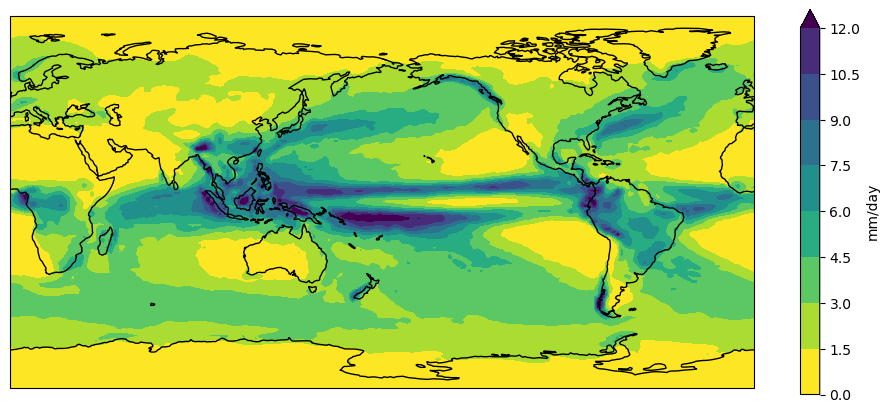

In [77]:
fig = plt.figure(figsize=[12,5]) #cria uma figura com largura de 12 e altura de 5

ax = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))#adiciona um subplot com projeção geográfica PlateCarree e centraliza o mapa no meridiano de 180 graus.

clim.plot.contourf(
    ax=ax,
    levels=np.arange(0, 13.5, 1.5),
    extend="max",
    transform=ccrs.PlateCarree(), #Define que os dados estão na projeção PlateCarree (latitude e longitude)
    cbar_kwargs={"label": clim.units}, # esta linha, no geral, Adiciona uma legenda para a barra de cores (colorbar) usando a unidade dos dados (clim.units), que provavelmente é mm/day.
    cmap="viridis_r", #inverte as cores, mais escuro#azul é mais precipitação
)
ax.coastlines()#Adiciona contornos de linhas de costa para delinear os continentes e ajudar na orientação geográfica.

plt.show()

In [75]:
print(clim.max)

<bound method DataArrayAggregations.max of <xarray.DataArray 'pr' (lat: 144, lon: 192)>
array([[0.15950695, 0.16463352, 0.16613839, ..., 0.17167493, 0.17302468,
        0.17006743],
       [0.16471735, 0.16434446, 0.16356934, ..., 0.16790195, 0.16573453,
        0.1647842 ],
       [0.18146767, 0.17692661, 0.17581128, ..., 0.19345854, 0.18982219,
        0.18698342],
       ...,
       [0.64894656, 0.64607999, 0.64531446, ..., 0.63382763, 0.63925537,
        0.63917372],
       [0.62067316, 0.61967841, 0.62144403, ..., 0.61821057, 0.6184225 ,
        0.61855632],
       [0.60785395, 0.60829043, 0.60762379, ..., 0.60819248, 0.60814875,
        0.6074299 ]])
Coordinates:
  * lon      (lon) float64 0.9375 2.812 4.688 6.562 ... 353.4 355.3 357.2 359.1
  * lat      (lat) float64 -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
Attributes:
    standard_name:  precipitation_flux
    long_name:      Precipitation
    units:          mm/day
    comment:        includes both liquid and solid ph

Season selection
Rather than plot the annual climatology, edit the code so that it plots the June-August (JJA) season.

(Hint: the groupby functionality can be used to group all the data into seasons prior to averaging over the time axis

In [87]:
clim=ds["pr"].groupby("time.season").mean("time", keep_attrs=True)
clim.data=clim.data*86400
clim.attrs["units"]="mm/day"
clim.sel(season="JJA").plot.contourf(
    ax=ax,
    levels=np.arange(0, 13.5, 1.5),
    extend="max",
    transform=ccrs.PlateCarree(), #Define que os dados estão na projeção PlateCarree (latitude e longitude)
    cbar_kwargs={"label": clim.units}, # esta linha, no geral, Adiciona uma legenda para a barra de cores (colorbar) usando a unidade dos dados (clim.units), que provavelmente é mm/day.
    cmap="viridis_r", #inverte as cores, mais escuro#azul é mais precipitação
)

ax.coastlines()#Adiciona contornos de linhas de costa para delinear os continentes e ajudar na orientação geográfica.

plt.show()

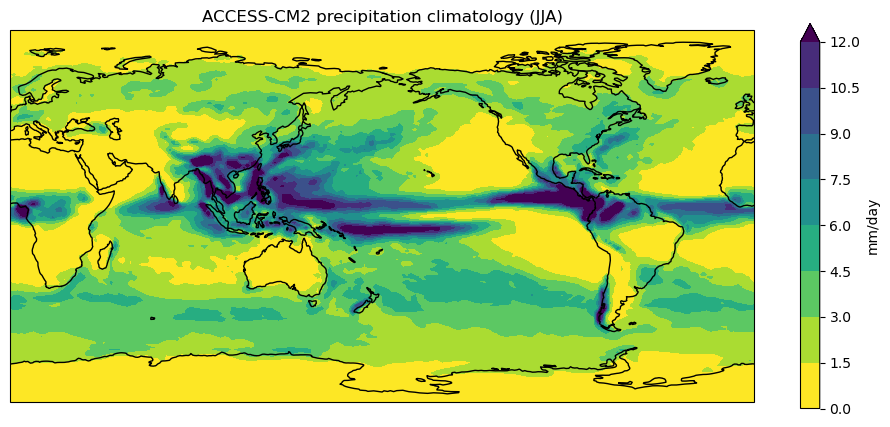

In [91]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np


accesscm2_pr_file = "data_carpentry/data/pr_Amon_ACCESS-CM2_historical_r1i1p1f1_gn_201001-201412.nc"

ds = xr.open_dataset(accesscm2_pr_file)

clim=ds["pr"].groupby("time.season").mean("time", keep_attrs=True)
clim.data=clim.data*86400
clim.attrs["units"]="mm/day"

fig = plt.figure(figsize=[12,5])
ax = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))
clim.sel(season="JJA").plot.contourf(
    ax=ax,
    levels=np.arange(0, 13.5, 1.5),
    extend="max",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={"label": clim.units},
    cmap="viridis_r",
)
model = ds.attrs["source_id"]
title = f"{model} precipitation climatology (JJA)"
plt.title(title)
ax.coastlines()
plt.show()

# Tentar com a temperatura

now, if we want to call different months or such, we create a function, so that we dont have to copy paste all the time

In [95]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np

accesscm2_pr_file = "data_carpentry/data/pr_Amon_ACCESS-CM2_historical_r1i1p1f1_gn_201001-201412.nc"

def plot_pr_climatology(pr_filr,season, gridlines=False):
    
    """Plot the precipitation climatology.
    
    Args:
      pr_file (str): Precipitation data file
      season (str): Season (3 letter abbreviation, e.g. JJA)
      gridlines (bool): Select whether to plot gridlines
    
    """    

    ds = xr.open_dataset(accesscm2_pr_file)

    clim=ds["pr"].groupby("time.season").mean("time", keep_attrs=True)
    clim.data=clim.data*86400
    clim.attrs["units"]="mm/day"

    fig = plt.figure(figsize=[12,5])
    ax = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))
    clim.sel(season="JJA").plot.contourf(
        ax=ax,
        levels=np.arange(0, 13.5, 1.5),
        extend="max",
        transform=ccrs.PlateCarree(),
        cbar_kwargs={"label": clim.units},
        cmap="viridis_r",
    )
    ax.coastlines()
    if gridlines:
        plt.gca().gridlines()
    model = ds.attrs["source_id"]
    title = f"{model} precipitation climatology (JJA)"
    plt.title(title)
    

    
    plt.show()

In [96]:
help(plot_pr_climatology)

Help on function plot_pr_climatology in module __main__:

plot_pr_climatology(pr_filr, season, gridlines=False)
    Plot the precipitation climatology.
    
    Args:
      pr_file (str): Precipitation data file
      season (str): Season (3 letter abbreviation, e.g. JJA)
      gridlines (bool): Select whether to plot gridlines



WE CAN NOW USE THIS FUNCTION TO CREATE EXACTLY THE SAME PLOT

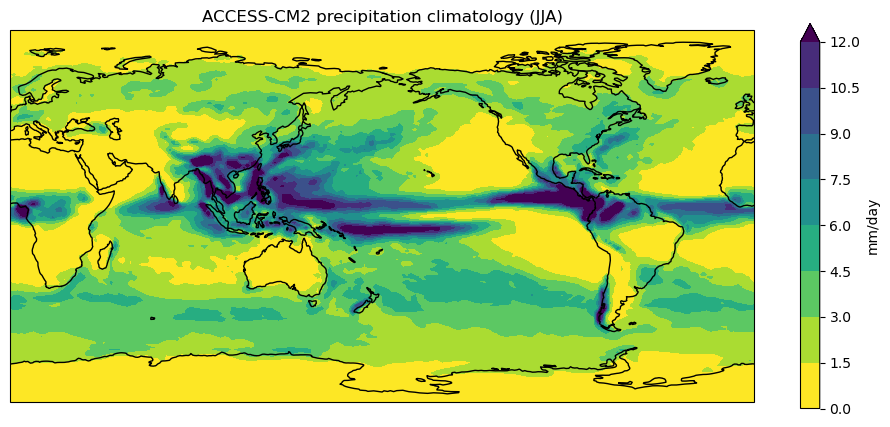

In [99]:
plot_pr_climatology("data_carpentry/data/pr_Amon_ACCESS-ESM1-5_historical_r1i1p1f1_gn_201001-201412.nc","DJF")

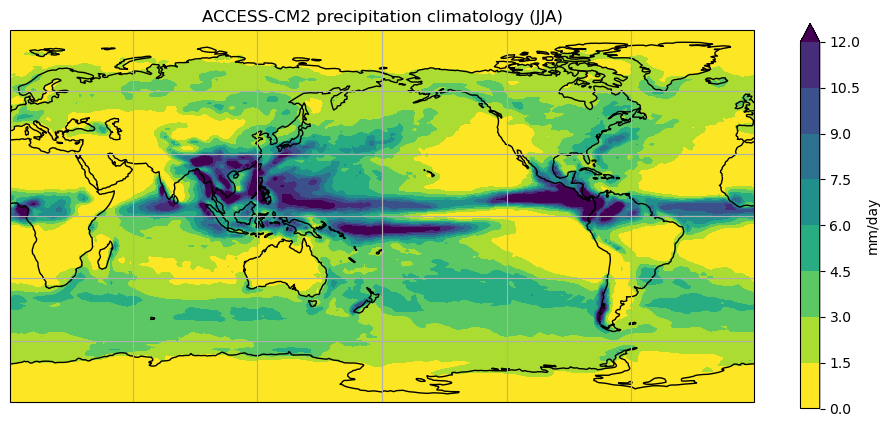

In [100]:
plot_pr_climatology("data_carpentry/data/pr_Amon_ACCESS-ESM1-5_historical_r1i1p1f1_gn_201001-201412.nc","DJF",   gridlines=True)

In [ ]:
def plot_pr_climatology(pr_file, season, gridlines=False):
    """Plot the precipitation climatology.

    Args:
      pr_file (str): Precipitation data file
      season (str): Season (3 letter abbreviation, e.g. JJA)
      gridlines (bool): Select whether to plot gridlines

    """

    ds = xr.open_dataset(pr_file)
    clim = ds["pr"].groupby("time.season").mean("time", keep_attrs=True)
    clim = convert_pr_units(clim)
    create_plot(clim, ds.attrs["source_id"], season, gridlines=gridlines)
    plt.show()

In [101]:
import unit_conversion
clim.data = unit_conversion.convert_pr_units(clim.data)

ModuleNotFoundError: No module named 'unit_conversion'